# 01 · EDA de calidad del aire

**Pregunta del TP:** ¿qué le pasa al aire porteño cuando paran los colectivos?

Antes de mirar los paros hay que conocer los datos: cuánto hay, cómo se distribuyen, qué tan contaminado
está el aire en un día común y qué lo hace variar. Este notebook es **univariado y temporal**; el cruce con
la actividad del transporte está en `04_bivariado`.

**Datos:** `gold_analitico` (una fila por estación y día). Fuente: informes mensuales públicos de la APrA,
estaciones **Parque Centenario**, **Córdoba** y **La Boca**. Usamos el **bloque de 8 a 16 h** (la ventana
diurna que publica la APrA, cuando circulan los colectivos) y el **promedio de 24 h** para comparar con la OMS.

Unidades: NO, NO2 y NOx en ppb; CO en ppm; PM10 en µg/m³. Los valores dudosos ya se filtraron en el pipeline
(ver tests de dbt): acá solo entran valores válidos y físicamente coherentes.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Dónde están los Parquet: export/ del repo (local, después de `uv run python run.py`)
# o la carpeta actual (Colab: subir los .parquet de export/ con el panel de archivos).
for BASE in [Path("../export"), Path("export"), Path(".")]:
    if (BASE / "gold_analitico.parquet").exists():
        break
else:
    raise FileNotFoundError("No encuentro gold_analitico.parquet: corré `uv run python run.py` o subilo a Colab")

d = pd.read_parquet(BASE / "gold_analitico.parquet")
d["fecha"] = pd.to_datetime(d["fecha"])
eventos = pd.read_parquet(BASE / "eventos.parquet")
eventos["fecha"] = pd.to_datetime(eventos["fecha"])

ESTACIONES = ["CENTENARIO", "CORDOBA", "LA BOCA"]
# Un color fijo por estación en todos los notebooks (paleta validada para daltonismo).
COLOR = {"CENTENARIO": "#2a78d6", "CORDOBA": "#eb6834", "LA BOCA": "#1baf7a"}
# Resaltado de eventos (solo en gráficos donde no se colorea por estación).
COLOR_EVENTO = {"sin_colectivos": "#6250d6", "control": "#eda100"}
GRIS, TINTA, TINTA_2 = "#b9b8b2", "#0b0b0b", "#52514e"

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 110, "font.size": 10, "text.color": TINTA,
    "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.titlelocation": "left", "axes.titleweight": "bold", "axes.titlesize": 11,
    "lines.linewidth": 2, "legend.frameon": False,
})
pd.options.display.float_format = "{:,.2f}".format
print(f"{len(d):,} filas (estación × día), {d.fecha.min():%d/%m/%Y} a {d.fecha.max():%d/%m/%Y}")

2,950 filas (estación × día), 01/01/2024 a 30/09/2026


## 1. ¿Cuántos datos tenemos?

Un día cuenta como "con dato" si tiene el promedio 8-16 h válido. El período tiene 1.004 días.

In [2]:
CONT = {"nox_816_ppb": "NOx", "no2_816_ppb": "NO2", "co_816_ppm": "CO", "pm10_816_ugm3": "PM10"}
dias_periodo = (d.fecha.max() - d.fecha.min()).days + 1
cobertura = (d.groupby("estacion")[list(CONT)].count().rename(columns=CONT) / dias_periodo * 100).round(0)
cobertura

,NOx,NO2,CO,PM10
estacion,,,,
CENTENARIO,64.00,65.00,91.00,93.00
CORDOBA,85.00,85.00,85.00,86.00
LA BOCA,93.00,93.00,92.00,83.00


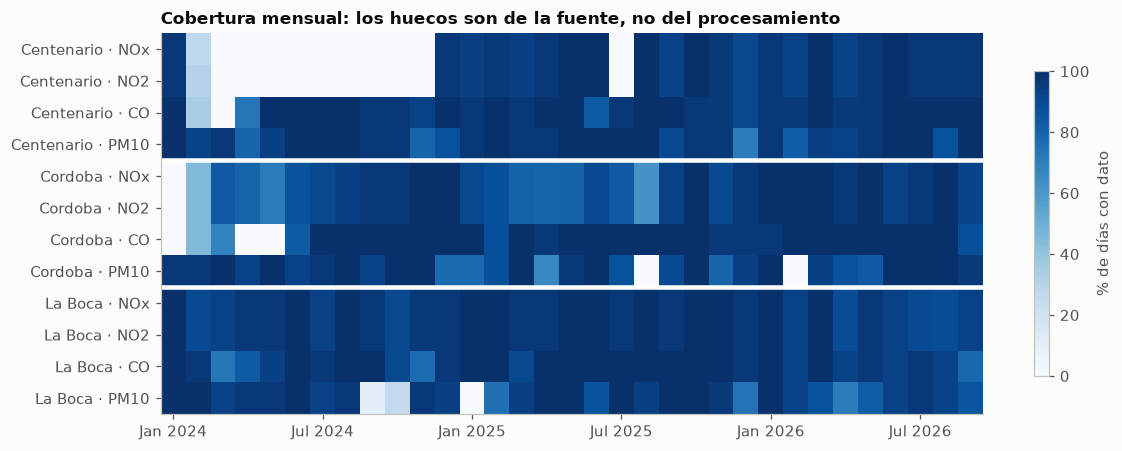

In [3]:
# Cobertura mensual: % de días del mes con dato 8-16 h, por estación y contaminante.
mes = d.assign(mes=d.fecha.dt.to_period("M"))
filas, matriz = [], []
for est in ESTACIONES:
    sub = mes[mes.estacion == est]
    dias_mes = sub.groupby("mes").size()
    for col, nombre in CONT.items():
        filas.append(f"{est.title()} · {nombre}")
        matriz.append((sub.groupby("mes")[col].count() / dias_mes * 100).reindex(sorted(mes.mes.unique())).values)
matriz = np.array(matriz, dtype=float)
meses = sorted(mes.mes.unique())

fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(matriz, aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
ax.set_yticks(range(len(filas)), filas)
ticks = [i for i, m in enumerate(meses) if m.month in (1, 7)]
ax.set_xticks(ticks, [meses[i].strftime("%b %Y") for i in ticks])
ax.grid(False)
for i in range(4, len(filas), 4):
    ax.axhline(i - 0.5, color="#fcfcfb", lw=3)
fig.colorbar(im, ax=ax, label="% de días con dato", shrink=0.8)
ax.set_title("Cobertura mensual: los huecos son de la fuente, no del procesamiento")
plt.tight_layout()

**Lectura.** Los huecos grandes vienen de la propia APrA (meses sin publicar o analizadores fuera de
servicio), no del pipeline:
- NOx y NO2 de **Centenario**: faltan de marzo a noviembre de 2024 y julio de 2025.
- **Córdoba**: falta enero de 2024 en óxidos de nitrógeno y CO, y el CO de abril y mayo de 2024.
- PM10 de **La Boca**: septiembre de 2024 figura como "no publicado".

Consecuencia para el estudio: **los dos paros de 2024 solo se pueden medir con NOx/CO en La Boca**.

## 2. Estadísticas descriptivas (bloque 8-16 h)

La mediana y el rango intercuartil (P25-P75) describen mejor que la media: las distribuciones son asimétricas
(ver punto 3).

In [4]:
COLS = {"no_816_ppb": "NO (ppb)", "no2_816_ppb": "NO2 (ppb)", "nox_816_ppb": "NOx (ppb)",
        "co_816_ppm": "CO (ppm)", "pm10_816_ugm3": "PM10 (µg/m³)", "nox_co_816": "NOx/CO"}
desc = (d.melt(id_vars="estacion", value_vars=list(COLS), var_name="variable", value_name="valor")
          .dropna()
          .groupby(["variable", "estacion"])["valor"]
          .describe(percentiles=[0.25, 0.5, 0.75, 0.95])
          .rename(index=COLS, level=0)
          [["count", "mean", "25%", "50%", "75%", "95%", "max"]])
desc.columns = ["n", "media", "P25", "mediana", "P75", "P95", "máx"]
desc.reindex(list(COLS.values()), level=0)

n  media    P25  mediana    P75    P95    máx
variable     estacion                                                     
NO (ppb)     CENTENARIO 648.00  21.74   9.75    15.00  27.25  60.30 136.00
             CORDOBA    855.00  36.11  16.00    29.00  48.00  82.00 424.00
             LA BOCA    936.00  27.38  11.00    22.00  35.00  71.25 209.00
NO2 (ppb)    CENTENARIO 648.00  13.70  10.00    13.00  17.00  24.00  46.00
             CORDOBA    855.00  19.53  14.00    19.00  24.00  33.00  70.00
             LA BOCA    936.00  27.72  20.00    26.00  35.00  48.00  66.00
NOx (ppb)    CENTENARIO 647.00  35.31  19.50    29.00  44.00  79.70 176.00
             CORDOBA    855.00  55.49  31.00    49.00  71.00 112.30 492.00
             LA BOCA    936.00  55.07  34.00    49.00  68.00 114.00 268.00
CO (ppm)     CENTENARIO 914.00   0.42   0.30     0.40   0.50   0.80   1.40
             CORDOBA    856.00   0.65   0.40     0.60   0.80   1.10   1.90
             LA BOCA    926.00   0.35   0.20     0.30   0.40   0.70   1.70
PM10 (µg/m³) CENTENARIO 936.00  23.08  16.00    21.00  28.00  42.00  99.00
             CORDOBA    866.00  28.05  21.00    26.00  34.00  48.00 119.00
             LA BOCA    830.00  27.30  18.00    24.50  33.00  54.55 128.00
NOx/CO       CENTENARIO 641.00  83.48  54.00    77.50 103.33 160.00 453.33
             CORDOBA    792.00  89.67  66.00    85.00 105.00 142.04 984.00
             LA BOCA    911.00 167.61 115.28   162.22 210.00 285.00 637.50

**Lectura.**
- **Córdoba** (avenida de tránsito pesado) tiene el NO más alto: el NO es el contaminante "fresco" que sale
  del caño de escape. **La Boca** tiene el NO2 más alto y Centenario es la más limpia en óxidos de nitrógeno.
- El **cociente NOx/CO** de La Boca casi duplica al de las otras dos: allí pesa mucho más el diésel
  (colectivos, camiones del puerto) respecto de los autos a nafta, que dominan el CO.
- El PM10 es parecido en las tres: depende más de fuentes regionales (polvo, quemas) que del tránsito local.

## 3. Distribuciones: por qué trabajamos con logaritmos

Las concentraciones son positivas y con cola larga a la derecha: muchos días moderados y pocos días muy altos.
En escala logarítmica la distribución se vuelve casi simétrica. Por eso el modelo del notebook `05_eventos` usa
`log(NOx)`: los efectos se leen como **porcentajes** y los días extremos no dominan el ajuste.

Asimetría lineal: 2.48 · asimetría en log: -0.27


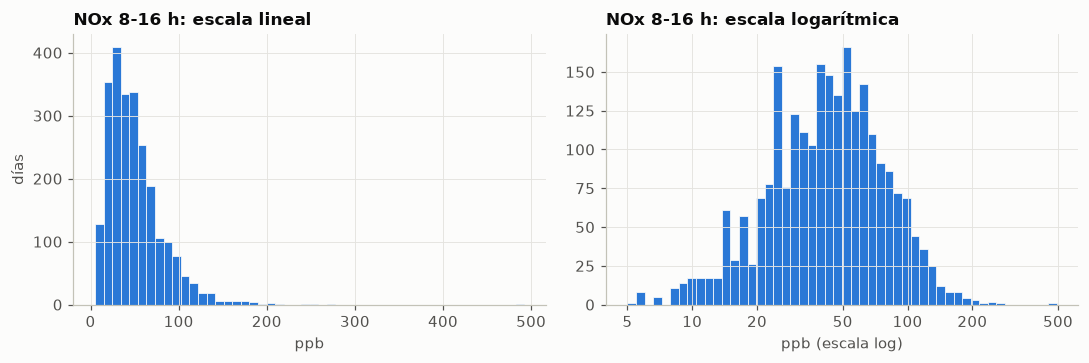

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
x = d["nox_816_ppb"].dropna()
axes[0].hist(x, bins=50, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.5)
axes[0].set(title="NOx 8-16 h: escala lineal", xlabel="ppb", ylabel="días")
axes[1].hist(np.log10(x), bins=50, color="#2a78d6", edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set(title="NOx 8-16 h: escala logarítmica", xlabel="ppb (escala log)")
axes[1].set_xticks(np.log10([5, 10, 20, 50, 100, 200, 500]), [5, 10, 20, 50, 100, 200, 500])
print(f"Asimetría lineal: {x.skew():.2f} · asimetría en log: {np.log(x).skew():.2f}")
plt.tight_layout()

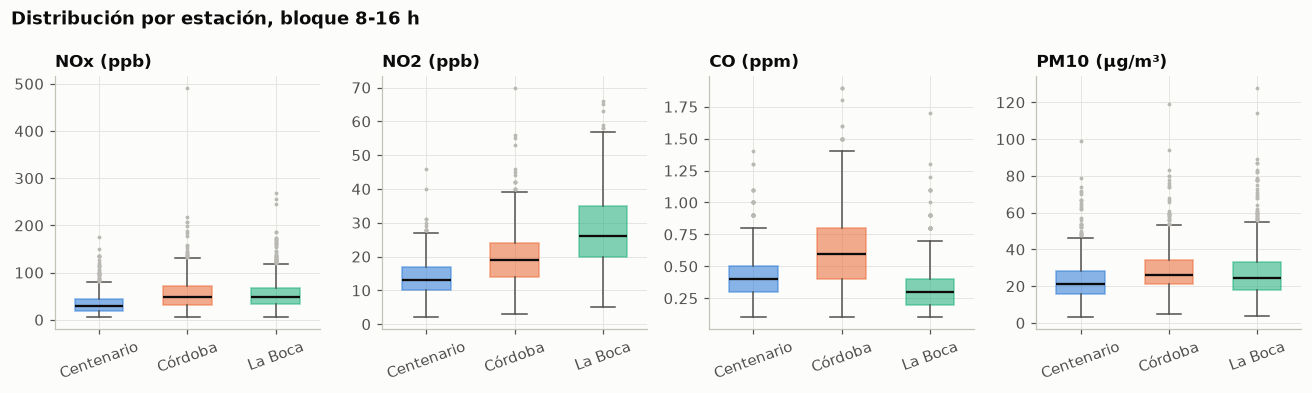

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3.6))
for ax, (col, nombre) in zip(axes, [("nox_816_ppb", "NOx (ppb)"), ("no2_816_ppb", "NO2 (ppb)"),
                                     ("co_816_ppm", "CO (ppm)"), ("pm10_816_ugm3", "PM10 (µg/m³)")]):
    datos = [d.loc[d.estacion == e, col].dropna() for e in ESTACIONES]
    bp = ax.boxplot(datos, widths=0.55, patch_artist=True, showfliers=True,
                    medianprops={"color": TINTA, "linewidth": 1.5},
                    flierprops={"marker": "o", "markersize": 2.5, "markerfacecolor": GRIS, "markeredgecolor": "none"},
                    whiskerprops={"color": TINTA_2}, capprops={"color": TINTA_2})
    for caja, est in zip(bp["boxes"], ESTACIONES):
        caja.set(facecolor=COLOR[est], alpha=0.55, edgecolor=COLOR[est])
    ax.set_xticks([1, 2, 3], ["Centenario", "Córdoba", "La Boca"], rotation=20)
    ax.set_title(nombre)
fig.suptitle("Distribución por estación, bloque 8-16 h", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()

## 4. ¿Qué tan contaminado está el aire? Comparación con la OMS

Guías de calidad del aire de la OMS (2021), promedio de 24 h: **NO2 25 µg/m³** y **PM10 45 µg/m³**
(la OMS admite superarlas 3-4 días por año). Anuales: NO2 10 µg/m³ y PM10 15 µg/m³.
Para comparar se pasa a masa (NO2: 1,88 µg/m³ por ppb a 25 °C), cálculo que ya hace el pipeline.

In [7]:
GUIA_24H = {"no2_24h_ugm3": 25, "pm10_24h_ugm3": 45}
GUIA_ANUAL = {"no2_24h_ugm3": 10, "pm10_24h_ugm3": 15}
tabla = []
for col, guia in GUIA_24H.items():
    g = d.dropna(subset=[col]).groupby(["estacion", "anio"])[col]
    t = pd.DataFrame({"días con dato": g.count(), "media (µg/m³)": g.mean(),
                      "% días sobre guía 24 h": g.apply(lambda s: (s > guia).mean() * 100)})
    t["media / guía anual"] = t["media (µg/m³)"] / GUIA_ANUAL[col]
    t.insert(0, "contaminante", "NO2" if col.startswith("no2") else "PM10")
    tabla.append(t)
oms = pd.concat(tabla).reset_index().set_index(["contaminante", "estacion", "anio"])
oms

días con dato  media (µg/m³)  \
contaminante estacion   anio                                 
NO2          CENTENARIO 2024             66          23.30   
                        2025            322          28.12   
                        2026            265          25.14   
             CORDOBA    2024            300          38.88   
                        2025            320          34.94   
                        2026            262          36.13   
             LA BOCA    2024            348          56.30   
                        2025            358          49.76   
                        2026            231          46.66   
PM10         CENTENARIO 2024            334          20.99   
                        2025            347          21.47   
                        2026            256          21.89   
             CORDOBA    2024            348          24.61   
                        2025            279          24.42   
                        2026            228          26.50   
             LA BOCA    2024            298          23.91   
                        2025            306          23.60   
                        2026            219          24.74   

                              % días sobre guía 24 h  media / guía anual  
contaminante estacion   anio                                              
NO2          CENTENARIO 2024                   33.33                2.33  
                        2025                   55.28                2.81  
                        2026                   48.68                2.51  
             CORDOBA    2024                   87.67                3.89  
                        2025                   78.12                3.49  
                        2026                   87.02                3.61  
             LA BOCA    2024                   95.69                5.63  
                        2025                   93.85                4.98  
                        2026                   94.37                4.67  
PM10         CENTENARIO 2024                    4.19                1.40  
                        2025                    1.15                1.43  
                        2026                    1.56                1.46  
             CORDOBA    2024                    3.74                1.64  
                        2025                    2.15                1.63  
                        2026                    3.95                1.77  
             LA BOCA    2024                    4.03                1.59  
                        2025                    4.25                1.57  
                        2026                    4.57                1.65

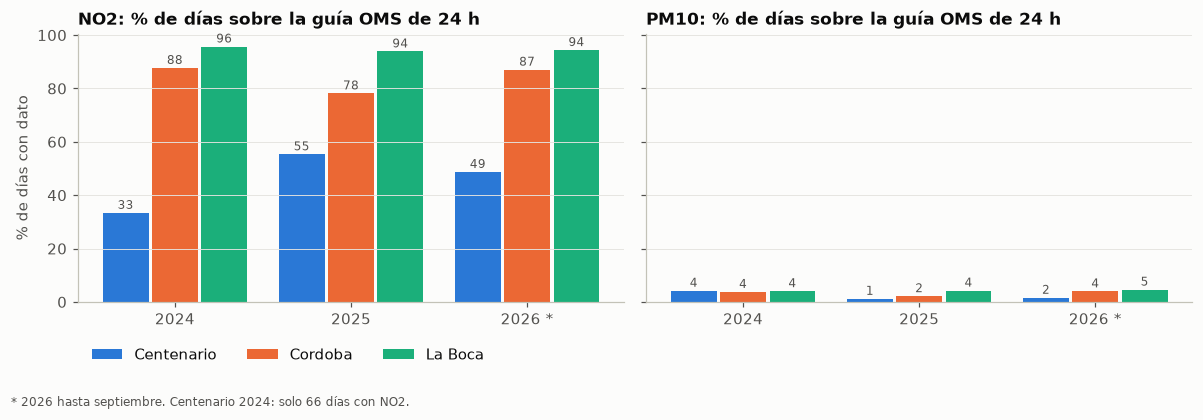

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
anios = sorted(d.anio.unique())
ancho = 0.26
for ax, cont in zip(axes, ["NO2", "PM10"]):
    sub = oms.loc[cont, "% días sobre guía 24 h"]
    for i, est in enumerate(ESTACIONES):
        vals = [sub.get((est, a), np.nan) for a in anios]
        xs = np.arange(len(anios)) + (i - 1) * (ancho + 0.02)
        ax.bar(xs, vals, width=ancho, color=COLOR[est], label=est.title())
        for xv, v in zip(xs, vals):
            if not np.isnan(v):
                ax.text(xv, v + 1.5, f"{v:.0f}", ha="center", fontsize=8, color=TINTA_2)
    ax.set_xticks(range(len(anios)), [str(a) + (" *" if a == 2026 else "") for a in anios])
    ax.set_title(f"{cont}: % de días sobre la guía OMS de 24 h")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("% de días con dato")
axes[0].legend(loc="upper left", bbox_to_anchor=(0, -0.12), ncol=3)
fig.text(0.01, -0.04, "* 2026 hasta septiembre. Centenario 2024: solo 66 días con NO2.", fontsize=8, color=TINTA_2)
plt.tight_layout()

In [9]:
co_max = d["co_24h_ppm"].max() * 1.145
print(f"CO: máximo promedio de 24 h del período = {co_max:.1f} mg/m³ (guía OMS de 24 h: 4 mg/m³)")

CO: máximo promedio de 24 h del período = 1.9 mg/m³ (guía OMS de 24 h: 4 mg/m³)


**Lectura.**
- **El NO2 es el problema:** en La Boca supera la guía de 24 h más del 90% de los días con dato; en Córdoba,
  entre el 78 y el 88%; en Centenario, la mitad. Los promedios anuales están entre 2,3 y 5,6 veces la guía anual.
- **El PM10 cumple la guía de 24 h casi siempre** (1-5% de los días), pero su promedio anual supera la guía
  anual de 15 µg/m³ en un 40-80%.
- Centenario 2024 tiene solo 66 días de NO2: ese año no es comparable.
- **El CO nunca se acerca a la guía.** No lo usamos como problema de salud sino como **trazador de los autos a
  nafta**: es lo que permite separar el aporte del diésel con el cociente NOx/CO.

## 5. Evolución en el tiempo

Mediana móvil de 28 días del NOx 8-16 h. Las líneas verticales marcan los seis eventos del estudio.

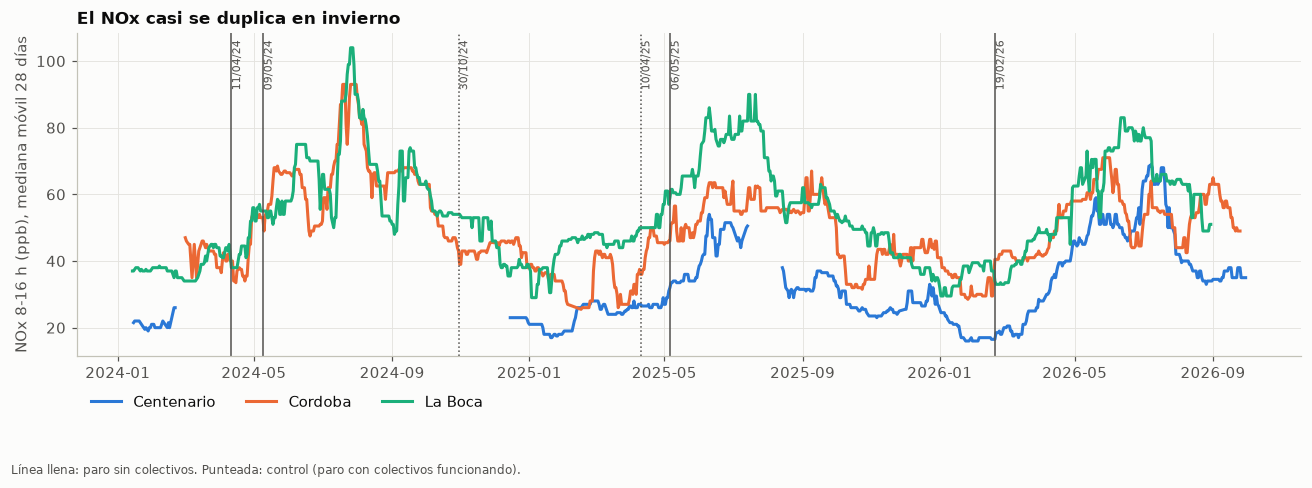

In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
for est in ESTACIONES:
    s = (d[d.estacion == est].set_index("fecha")["nox_816_ppb"].sort_index()
         .rolling("28D", min_periods=14).median())
    ax.plot(s.index, s.values, color=COLOR[est], label=est.title())
for _, ev in eventos.iterrows():
    estilo = "-" if ev.grupo == "sin_colectivos" else ":"
    ax.axvline(ev.fecha, color=TINTA_2, lw=1, ls=estilo)
    ax.text(ev.fecha, ax.get_ylim()[1] * 0.98, f" {ev.fecha:%d/%m/%y}", rotation=90, va="top",
            fontsize=7.5, color=TINTA_2)
ax.set(ylabel="NOx 8-16 h (ppb), mediana móvil 28 días")
ax.set_title("El NOx casi se duplica en invierno")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.08), ncol=3)
fig.text(0.01, -0.09, "Línea llena: paro sin colectivos. Punteada: control (paro con colectivos funcionando).",
         fontsize=8, color=TINTA_2)
plt.tight_layout()

In [11]:
estacional = (d.assign(estacion_anio=d.mes.map({12: "verano", 1: "verano", 2: "verano", 3: "otoño", 4: "otoño",
                                                 5: "otoño", 6: "invierno", 7: "invierno", 8: "invierno",
                                                 9: "primavera", 10: "primavera", 11: "primavera"}))
               .groupby(["estacion", "estacion_anio"])["nox_816_ppb"].median().unstack()
               [["verano", "otoño", "invierno", "primavera"]])
estacional

estacion_anio,verano,otoño,invierno,primavera
estacion,,,,
CENTENARIO,21.00,32.00,42.00,30.00
CORDOBA,37.00,51.00,56.00,45.00
LA BOCA,38.00,52.00,67.00,50.00


**Lectura.** En invierno la mediana del NOx es casi el doble que en verano en las tres estaciones. No es que haya más
tránsito: hay menos viento, inversiones térmicas y menos mezcla vertical, así que lo emitido se acumula.
**Por eso no alcanza con comparar un paro contra "un día cualquiera"**: hay que comparar contra días
parecidos (mismo mes, mismo día de la semana) y descontar el efecto del viento y la temperatura (notebook 05).

## 6. Ciclo semanal: la huella del tránsito

Si el NOx viene del tránsito, tiene que caer el fin de semana. Mediana por día de la semana, bloque 8-16 h.

Domingo respecto de la mediana de lunes a viernes (%):
              NOx     CO
estacion                
CENTENARIO -62.00 -25.00
CORDOBA    -53.00 -43.00
LA BOCA    -46.00 -33.00


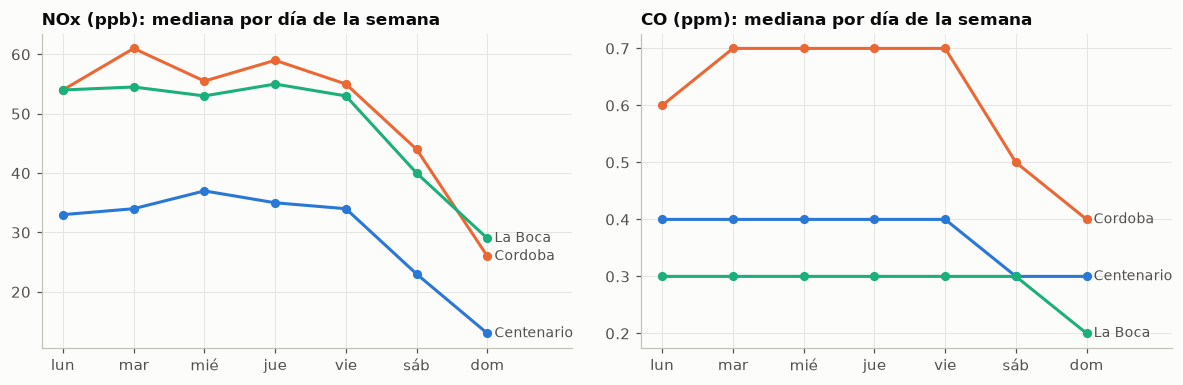

In [12]:
DIAS = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (col, nombre) in zip(axes, [("nox_816_ppb", "NOx (ppb)"), ("co_816_ppm", "CO (ppm)")]):
    sem = d.groupby(["estacion", "dia_semana"])[col].median().unstack(0)
    for est in ESTACIONES:
        ax.plot(range(7), sem[est].values, color=COLOR[est], marker="o", markersize=5, label=est.title())
        ax.text(6.1, sem[est].iloc[-1], est.title(), color=TINTA_2, va="center", fontsize=9)
    ax.set_xticks(range(7), DIAS)
    ax.set_xlim(-0.3, 7.2)
    ax.set_title(f"{nombre}: mediana por día de la semana")
plt.tight_layout()

caida = d.groupby(["estacion", "dia_semana"])[["nox_816_ppb", "co_816_ppm"]].median()
habiles = caida.loc[(slice(None), [1, 2, 3, 4, 5]), :].groupby("estacion").median()
domingo = caida.xs(7, level="dia_semana")
print("Domingo respecto de la mediana de lunes a viernes (%):")
print(((domingo / habiles - 1) * 100).round(0).rename(columns={"nox_816_ppb": "NOx", "co_816_ppm": "CO"}))

**Lectura.** El domingo el NOx cae más que el CO en las tres estaciones (la diferencia es mayor en Centenario
y menor en Córdoba). Tiene sentido: el domingo casi no circulan camiones
y circulan menos colectivos (diésel, mucho NOx), mientras que los autos (nafta, mucho CO) bajan menos.
Es la primera señal de que el cociente NOx/CO sirve como **firma del diésel**.

## 7. Valores extremos

Regla de Tukey sobre el logaritmo del NOx 8-16 h, por estación: es atípico lo que cae a más de 1,5 rangos
intercuartiles de la caja. **No se eliminan**: son días reales (el pipeline ya descartó los físicamente
imposibles). Sirven para entender qué los produce.

In [13]:
x = d.dropna(subset=["nox_816_ppb"]).copy()
x["log_nox"] = np.log(x["nox_816_ppb"])
q1 = x.groupby("estacion")["log_nox"].transform(lambda s: s.quantile(0.25))
q3 = x.groupby("estacion")["log_nox"].transform(lambda s: s.quantile(0.75))
at = x[(x.log_nox > q3 + 1.5 * (q3 - q1)) | (x.log_nox < q1 - 1.5 * (q3 - q1))]
print(at.groupby("estacion").size().rename("días atípicos").to_string(), "\n")
(at.sort_values("nox_816_ppb", ascending=False)
   [["estacion", "fecha", "nombre_dia", "tipo_dia", "evento", "nox_816_ppb", "viento_kmh", "temp_c"]]
   .head(12))

estacion
CENTENARIO     2
CORDOBA        4
LA BOCA       15 



,estacion,fecha,nombre_dia,tipo_dia,evento,nox_816_ppb,viento_kmh,temp_c
1835,CORDOBA,2026-05-23,sábado,sábado,NaN,492.00,10.50,12.15
261,LA BOCA,2025-06-19,jueves,hábil,NaN,268.00,4.50,10.60
267,LA BOCA,2025-07-02,miércoles,hábil,NaN,255.00,6.00,5.00
715,LA BOCA,2025-06-07,sábado,sábado,NaN,246.00,2.50,12.30
2255,CENTENARIO,2025-06-19,jueves,hábil,NaN,176.00,4.50,10.60
938,LA BOCA,2024-01-01,lunes,feriado,NaN,12.00,16.00,24.80
162,LA BOCA,2024-12-07,sábado,sábado,NaN,12.00,13.00,17.30
166,LA BOCA,2024-12-14,sábado,sábado,NaN,11.00,13.00,23.40
635,LA BOCA,2025-01-03,viernes,hábil,NaN,11.00,8.50,23.05
480,LA BOCA,2024-02-13,martes,feriado,NaN,11.00,12.00,19.25


In [14]:
altos = at[at.nox_816_ppb > at.groupby("estacion").nox_816_ppb.transform("median")]
print(f"Viento mediano en los días atípicos altos: {altos.viento_kmh.median():.1f} km/h")
print(f"Viento mediano en todos los días:          {d.drop_duplicates('fecha').viento_kmh.median():.1f} km/h")

Viento mediano en los días atípicos altos: 8.0 km/h
Viento mediano en todos los días:          10.5 km/h


**Lectura.** Hay pocos atípicos (21 en total) y de dos tipos:
- **Altos:** días de invierno con muy poco viento (2,5 a 6 km/h): episodios de estancamiento, no errores.
  La excepción a revisar es Córdoba el sábado 23/05/2026 (492 ppb con viento normal): puede ser una fuente
  local puntual o un problema del analizador.
- **Bajos:** casi todos en La Boca, en feriados, fines de semana y días de verano. **Entre ellos aparece el paro
  general del 19/02/2026**, uno de los días con menos NOx de La Boca en todo el período.

Refuerza lo del punto 5: antes de atribuirle una suba o una caída al tránsito hay que controlar el viento.

## Hallazgos del EDA de calidad del aire

1. **Datos:** cobertura buena salvo huecos de la fuente (NOx de Centenario en 2024, CO de Córdoba abr-may 2024).
   Los paros de 2024 se miden solo en La Boca.
2. **El NO2 supera la guía de 24 h de la OMS la gran mayoría de los días** en Córdoba y La Boca; el PM10 cumple
   la guía diaria pero no la anual; el CO nunca se acerca a su guía (lo usamos como trazador de la nafta).
3. **Distribuciones asimétricas** → trabajamos en escala logarítmica (efectos en %).
4. **La meteorología manda:** el NOx de invierno casi duplica al de verano y los picos coinciden con días sin
   viento. Cualquier comparación de un paro tiene que controlar viento, temperatura, mes y día de la semana.
5. **El tránsito se ve en el ciclo semanal:** el domingo el NOx cae entre 46 y 62% y el CO entre 25 y 43%,
   consistente con que el diésel (colectivos y camiones) aporta buena parte del NOx y la nafta, del CO.
6. **Un dato llamativo:** el paro del 19/02/2026 figura entre los días de NOx más bajo de La Boca.

**Siguiente:** `04_bivariado` cruza estas concentraciones con la actividad de los colectivos (SUBE).